# E13 · Spectral indices as extra input channels

E12 ended with: *further gains need a new signal for the vegetation classes, not another round.* E13 gives the network
that signal directly. Next to the 12 bands it gets five normalised differences (`src/indices.py`) that say what each
pixel is made of:

| Index | Formula | Shows |
|---|---|---|
| NDVI | (B08 − B04) / (B08 + B04) | green vegetation |
| NDWI | (B03 − B08) / (B03 + B08) | open water |
| MNDWI | (B03 − B11) / (B03 + B11) | water, separated from built-up |
| NDBI | (B11 − B08) / (B11 + B08) | built-up and bare soil |
| NDRE | (B8A − B05) / (B8A + B05) | red edge: vegetation type and vigour |

The **labels do not change**: Kaggle only scores the 10 EuroSAT classes, so "water", "vegetation" and "built-up" enter
as inputs, not as new classes. The indices are computed inside the model (`SpectralIndexLayer`, a fixed input layer like
E05c's equaliser), from the `hist_split`-corrected values, so Kaggle images get them the same way at prediction time.

Everything else is the **E09a setup** (best model, 72.67%): EfficientNet-B0, 12 bands, `hist_split`, contrast
augmentation, round-3 pseudo-labels (E06c + AdaBN teacher, 8 views agree, SeaLake capped at 400, used 2× per epoch).
One change: the index channels.

**Caveat.** Ratios cancel a common brightness factor but not an additive haze offset, and NDVI is known to be higher on
atmospherically corrected (L2A) data than on L1C. Section 2 checks how far the indices still differ between EuroSAT and
Kaggle before training.

**Train or load.** `LOAD_RUNS["E13a"] = None` trains (about 25 minutes on an M4 GPU). After training, set it to the new
run folder and commit the weights if the run is submitted (`git add -f runs/<run>/model.pt`).

## 1 · Setup and data

In [1]:
import json
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, TEST_BANDS
from src.experiment import (add_pseudo_labels, class_mix, compare_variants, find_run, finish_run, kaggle_monitor,
                            kaggle_score, load_experiment_data, load_saved_model, plot_class_mix,
                            plot_variant_curves, select_view_agree, teacher_predictions, view_agreement)
from src.indices import DEFAULT_INDICES, compute_indices_np, index_stats
from src.models import MEDIUM_TRACK_LIMIT, build_model
from src.plot_style import apply_style
from src.training import Normalizer, TrainConfig, fit, load_run, predict_views
from src.utils import describe_device, get_device, seed_everything

apply_style()

# ---- Experiment settings ---------------------------------------------------------------
NOTEBOOK = "E13_spectral_indices"
LOAD_RUNS = {   # saved runs; None = train this variant again
    "E13a": None,
}
INDICES = list(DEFAULT_INDICES)   # NDVI, NDWI, MNDWI, NDBI, NDRE
REFERENCE = "pl_r3_view_agree_contrast_aug_hist_split_effb0"               # E09a, no AdaBN, 72.67%
R3_TEACHER = "adabn_balanced_pseudo_label_r2_x2_contrast_aug_hist_split_effb0"   # E06c + AdaBN: round-3 labels
CAPS = {"SeaLake": 400}        # as in E09a
REPEAT = 2                     # as in E09a
MODEL = "efficientnet_b0"
BANDS = list(TEST_BANDS)
SEED = 42
cfg = TrainConfig(epochs=20, batch_size=128, lr=1e-3, weight_decay=1e-4,
                  label_smoothing=0.1, patience=5, augment=True,
                  photometric={"contrast": (0.9, 1.5), "band_contrast": (0.9, 1.15),
                               "brightness": (0.93, 1.07), "p": 0.8})   # as in E09a
# -----------------------------------------------------------------------------------------

seed_everything(SEED)
device = get_device()              # CUDA > Apple GPU (MPS) > CPU
print("Device:", describe_device(device))
results = {}                        # variant -> RunResult, compared at the end

data = load_experiment_data(BANDS, ["hist_split"], device)
print(data.summary())


def base_config(variant, run_name, description, extra):
    return {"run_name": run_name, "description": description, "notebook": NOTEBOOK, "variant": variant,
            "model": MODEL, "bands": BANDS, "corrections": ["hist_split"], "train": asdict(cfg),
            "split": "split_seed42", **extra}

Device: Apple GPU (MPS)
Reading patch coordinates (one-time)...


Caching test images: 100%|██████████| 4232/4232 [00:00<00:00, 4713.82it/s]


train 18,900  val 4,050  internal test 4,050  Kaggle test 4,232


## 2 · Do the indices transfer from EuroSAT to Kaggle?

Mean index per class on the training split, and the same mean over all Kaggle images next to the training mean.
A large train/Kaggle difference in one index means the model may learn a value that does not hold on Kaggle.

In [2]:
tr_idx = compute_indices_np(data.X_tr, BANDS, INDICES).mean(axis=(2, 3))   # (N, n_indices), image means
kg_idx = compute_indices_np(data.X_kg, BANDS, INDICES).mean(axis=(2, 3))
per_class = pd.DataFrame(tr_idx, columns=INDICES).groupby(np.array(CLASSES)[data.y_tr]).mean().reindex(CLASSES)
display(per_class.round(3).style.background_gradient(axis=0, cmap="RdYlGn"))
pd.DataFrame({"EuroSAT train (hist_split)": tr_idx.mean(0), "Kaggle": kg_idx.mean(0),
              "difference": kg_idx.mean(0) - tr_idx.mean(0)}, index=INDICES).round(3)

,NDVI,NDWI,MNDWI,NDBI,NDRE
AnnualCrop,0.531000,-0.554000,-0.449000,-0.160000,0.392000
Forest,0.870000,-0.793000,-0.561000,-0.424000,0.644000
HerbaceousVegetation,0.595000,-0.581000,-0.532000,-0.085000,0.371000
Highway,0.630000,-0.588000,-0.459000,-0.205000,0.440000
Industrial,0.420000,-0.380000,-0.308000,-0.096000,0.271000
Pasture,0.819000,-0.730000,-0.518000,-0.351000,0.581000
PermanentCrop,0.542000,-0.548000,-0.487000,-0.093000,0.375000
Residential,0.554000,-0.516000,-0.419000,-0.136000,0.367000
River,0.504000,-0.394000,-0.280000,-0.182000,0.353000
SeaLake,-0.036000,0.139000,0.252000,-0.116000,-0.087000


,EuroSAT train (hist_split),Kaggle,difference
NDVI,0.534,0.439,-0.095
NDWI,-0.487,-0.393,0.094
MNDWI,-0.370,-0.284,0.087
NDBI,-0.182,-0.164,0.017
NDRE,0.364,0.299,-0.065


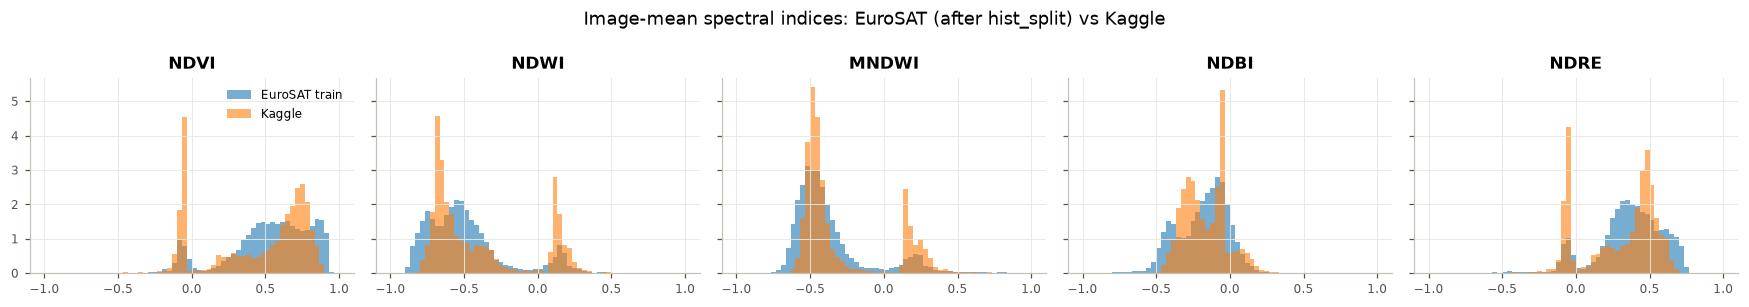

In [3]:
fig, axes = plt.subplots(1, len(INDICES), figsize=(3.2 * len(INDICES), 2.8), sharey=True)
for k, (ax, name) in enumerate(zip(axes, INDICES)):
    bins = np.linspace(-1, 1, 61)
    ax.hist(tr_idx[:, k], bins, density=True, alpha=0.6, label="EuroSAT train")
    ax.hist(kg_idx[:, k], bins, density=True, alpha=0.6, label="Kaggle")
    ax.set_title(name)
axes[0].legend()
fig.suptitle("Image-mean spectral indices: EuroSAT (after hist_split) vs Kaggle")
plt.tight_layout()

## 3 · Round-3 pseudo-labels (as in E09a)

In [4]:
table, _ = teacher_predictions(R3_TEACHER, data, device)
hard_idx = select_view_agree(table, CAPS, SEED)
print(f"{len(hard_idx):,} pseudo-labels (E09a: 2,948)")
tr_images, tr_labels, _ = add_pseudo_labels(data, table, hard_idx, repeat=REPEAT)

2,948 pseudo-labels (E09a: 2,948)
Pseudo-labelled Kaggle images: 2,948 of 4,232, used 2x (23.8% of the training set, 24,796 images)


## 4 · E13a · E09a + spectral index channels

The index statistics come from the EuroSAT training split only (like the normaliser) and are stored in the input layer,
so a saved run rebuilds exactly the same layer from `config.json`.

In [5]:
if LOAD_RUNS["E13a"]:
    model, normalizer, history = load_saved_model(LOAD_RUNS["E13a"], device)
    best_state = None
    INPUT_LAYER = json.loads((PROJECT_ROOT / LOAD_RUNS["E13a"] / "config.json").read_text())["input_layer"]
else:
    seed_everything(SEED)
    normalizer = Normalizer.fit(data.X_tr)
    idx_mean, idx_std = index_stats(data.X_tr, BANDS, INDICES)
    INPUT_LAYER = {"type": "spectral_indices", "indices": INDICES,
                   "band_mean": normalizer.mean, "band_std": normalizer.std,
                   "index_mean": idx_mean, "index_std": idx_std}
    model = build_model(MODEL, bands=BANDS, pretrained=True, input_layer=INPUT_LAYER).to(device)
    history, best_state = fit(model, tr_images, tr_labels, data.va_images, data.va_labels,
                              normalizer, cfg, monitor=kaggle_monitor(data, normalizer))

results["E13a"] = finish_run(model, normalizer, history, best_state, data, variant="E13a", load_run=LOAD_RUNS["E13a"],
    device=device, seed=SEED, param_limit=MEDIUM_TRACK_LIMIT,
    config=base_config("E13a", "indices_pl_r3_view_agree_contrast_aug_hist_split_effb0",
                       "E09a + spectral index channels (NDVI, NDWI, MNDWI, NDBI, NDRE)",
                       {"input_layer": INPUT_LAYER,
                        "pseudo_labels": {"teacher": R3_TEACHER, "selection": "view_agree", "caps": CAPS,
                                          "repeat": REPEAT, "n_images": int(len(hard_idx))}}))
del tr_images, tr_labels

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /Users/pananyar/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 22.9MB/s]


epoch  1  train loss 1.480 acc 0.598  val loss 0.307 acc 0.929 *  val_conf 0.835  kg_conf 0.736  kg_sealake 0.243  kg_share_AnnualCrop 0.113  kg_share_Forest 0.135  kg_share_HerbaceousVegetation 0.079  kg_share_Highway 0.079  kg_share_Industrial 0.059  kg_share_Pasture 0.070  kg_share_PermanentCrop 0.080  kg_share_Residential 0.091  kg_share_River 0.051  kg_share_SeaLake 0.243  (56s)
epoch  2  train loss 0.724 acc 0.916  val loss 0.189 acc 0.967 *  val_conf 0.877  kg_conf 0.784  kg_sealake 0.241  kg_share_AnnualCrop 0.085  kg_share_Forest 0.127  kg_share_HerbaceousVegetation 0.087  kg_share_Highway 0.082  kg_share_Industrial 0.060  kg_share_Pasture 0.086  kg_share_PermanentCrop 0.087  kg_share_Residential 0.090  kg_share_River 0.054  kg_share_SeaLake 0.241  (47s)
epoch  3  train loss 0.654 acc 0.942  val loss 0.185 acc 0.968 *  val_conf 0.885  kg_conf 0.833  kg_sealake 0.244  kg_share_AnnualCrop 0.108  kg_share_Forest 0.144  kg_share_HerbaceousVegetation 0.075  kg_share_Highway 0.073  

## 5 · Comparison with E09a (no AdaBN)

Same training data, only the index channels differ. Where do the predictions change? E12 found the remaining errors in
the vegetation pairs (AnnualCrop ↔ PermanentCrop, Forest ↔ HerbaceousVegetation, PermanentCrop ↔ Pasture), so those
are the rows to watch.

In [6]:
ref_dir = find_run(REFERENCE)
r_model, r_norm, _ = load_run(ref_dir, device)
ref_views = predict_views(r_model, data.kg_images, r_norm)
ref_prob = ref_views.mean(0)
summary = compare_variants(results, reference=ref_prob, reference_name="E09a")
r_metrics = json.loads((ref_dir / "metrics.json").read_text())
summary.loc["E09a (reference)"] = {"description": "best model, no AdaBN",
                                   "internal test (%)": r_metrics["internal_test_acc"] * 100,
                                   "confidence (%)": ref_prob.max(1).mean() * 100,
                                   "view agreement (%)": view_agreement(ref_views) * 100,
                                   "same class as E09a (%)": 100.0, "Kaggle public (%)": kaggle_score(ref_dir)}
summary.round(2)

,description,internal test (%),confidence (%),view agreement (%),same class as E09a (%),Kaggle public (%)
E13a,"E09a + spectral index channels (NDVI, NDWI, MN...",98.888889,84.697678,88.89414,94.990548,None
E09a (reference),"best model, no AdaBN",98.864198,87.362061,90.500945,100.0,72.671


In [7]:
# Different predictions: E09a's class (rows) -> E13a's class (no AdaBN) (columns)
ref_pred = np.array(CLASSES)[ref_prob.argmax(1)]
for k, r in results.items():
    new = np.array(CLASSES)[r.kg_prob.argmax(1)]
    changed = new != ref_pred
    print(f"{k}: {changed.sum()} images differ from E09a ({changed.mean():.1%})")
    display(pd.crosstab(ref_pred[changed], new[changed]).rename_axis(index="E09a", columns=k))

E13a: 188 images differ from E09a (4.4%)


E13a,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
E09a,,,,,,,,,,
AnnualCrop,0,0,2,5,0,5,15,0,1,0
Forest,1,0,29,0,0,6,2,0,2,0
HerbaceousVegetation,2,5,0,0,0,7,3,3,2,0
Highway,0,0,0,0,3,3,3,1,0,0
Industrial,0,0,2,2,0,0,2,8,1,0
Pasture,3,1,3,0,2,0,6,1,0,0
PermanentCrop,15,3,4,3,3,16,0,0,0,0
Residential,0,0,1,0,2,2,3,0,1,0
River,0,0,1,0,0,0,0,0,0,1


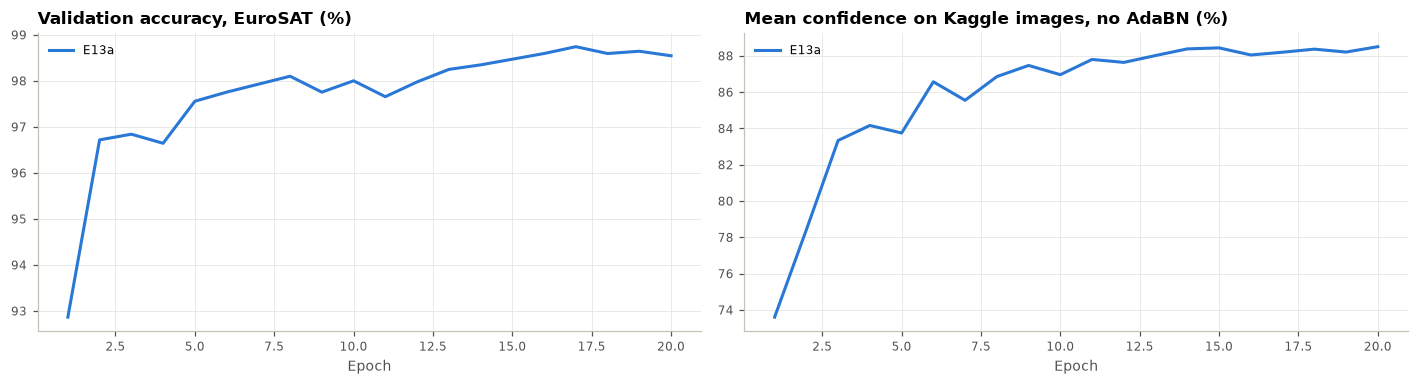

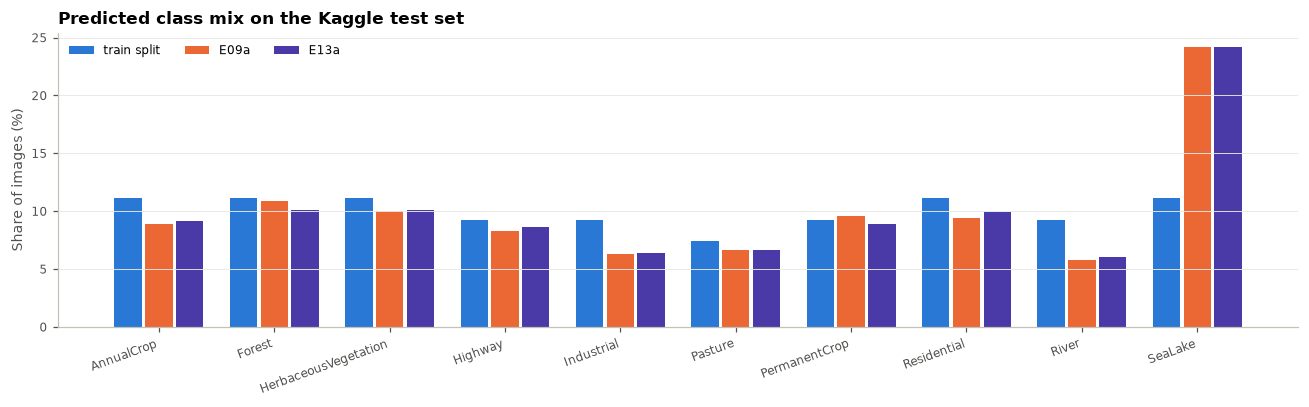

In [8]:
plot_variant_curves(results)
plot_class_mix(pd.DataFrame({"train split": class_mix(np.eye(10)[data.y_tr]), "E09a": class_mix(ref_prob),
                             **{k: class_mix(r.prob_ada) for k, r in results.items()}}))

## 6 · Conclusion

*To fill in after the Kaggle submission (both files: with and without AdaBN).*

| Model | Input | Internal test | Kaggle public (no AdaBN / AdaBN) |
|---|---|---|---|
| E09a | 12 bands | 98.86% | **72.67%** / 71.78% |
| E13a | 12 bands + 5 indices | | |